## Climatology Comparison
In this notebook we compare the climatology of atmospheric blocking with ad without the activation of detection filters

In [2]:
import numpy as np
import numpy.ma as ma
import xarray as xr
import cartopy.crs as ccrs
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.pyplot as plt
from tqdm import tqdm

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

In [3]:
%cd /emmy-noether/home/mf671/DATA/ERA5/gr_tracking
!ls

/emmy-noether/home/mf671/DATA/ERA5/gr_tracking
dictionaries
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_tyrlis.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_tyrlis_YMONMEAN.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_YMONMEAN.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1990-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_djf_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_jja_1940-2023_tyrlis.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023_tyrlis.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023_95perc.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023_md500.nc
ERA5_northem_2.5x2.5_zg_GHA_tracked_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg

In [20]:
#LOADING DATASET
ds = xr.load_dataset('ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023_tyrlis.nc')
ds2 = xr.load_dataset('ERA5_northem_2.5x2.5_zg_DAV_tracked_daily_1940-2023.nc')

frequency_base = ds['DAV_freq']
frequency_filt = ds2['DAV_freq']

lon = ds["lon"].values
lat = ds["lat"].values
zg = ds["zg"].values/9.8

ds.close()

lon = ds["lon"]
lat = ds["lat"]

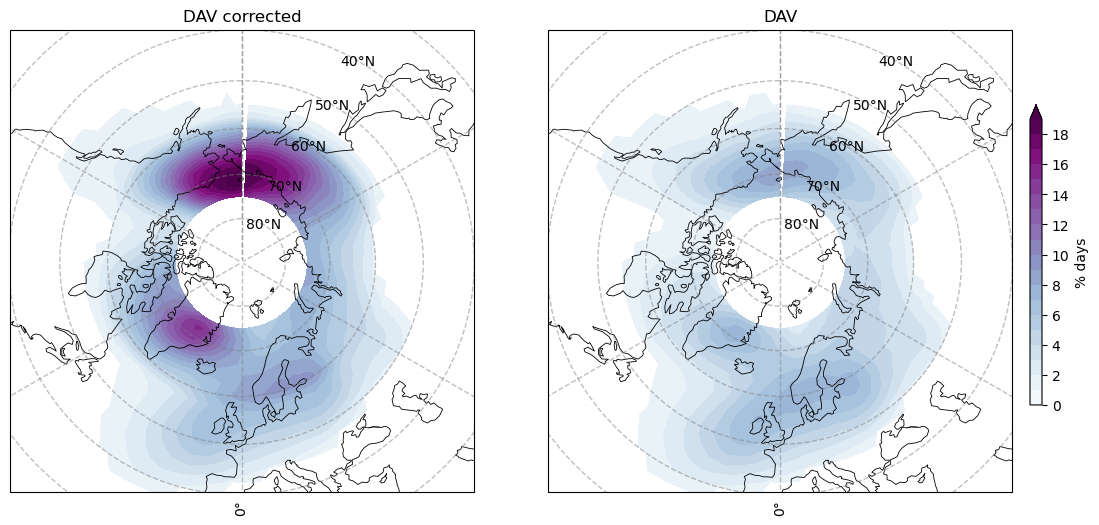

In [21]:
#%matplotlib qt5


fig,ax = plt.subplots(nrows=1,ncols=2,figsize=(12,6),subplot_kw={'projection': ccrs.NorthPolarStereo()})
ax.flatten()
titles = ("DAV corrected",
         "DAV")
for i,field in enumerate((frequency_base,frequency_filt)):
    field = ma.masked_array(field,field<1)
    extent =[-180,180,40,90]
    ax[i].set_extent(extent, ccrs.PlateCarree())
    ax[i].coastlines(linewidth = 0.6)
    gl = ax[i].gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                    linewidth=1, 
                    color='gray', 
                    alpha=0.5, 
                    linestyle='--')

    gl.top_labels=False
    gl.right_labels=False
    cont = ax[i].contourf(lon,lat,field,
                          np.arange(0,20,1),
                          extent=[0,90,-180,180],
                          extend = 'max',
                          cmap = "BuPu",
                          transform = ccrs.PlateCarree())
    ax[i].set_title(titles[i])

fig.subplots_adjust(top=0.88,
bottom=0.1,
left=0.065,
right=0.9,
hspace=0.2,
wspace=0.16)

cbar_ax = fig.add_axes([0.915,0.25,0.01,0.5])
cbar = plt.colorbar(cont, cax=cbar_ax, orientation='vertical',label="% days",pad=0.08, aspect=60)

plt.show()